# Single layer — strain-prior figure

The strain-prior figure, made only from saved files
(`results/strain_prior.npz` from `03e`, and the single layer's digitised horizons):
numpy and matplotlib. Writes `figures/fig03_single_layer_strain_prior`.

In [13]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
import cmasher as cmr

import sys
sys.path.insert(0, str(Path("..").resolve()))                      # publication/: figstyle
import figstyle
import single_layer_inputs as sli
figstyle.apply()

DATA_DIR = Path("data")
RES = Path("./results/strain_prior.npz")
FIG_DIR = Path("./figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

truth = sli.load_truth(DATA_DIR)
obs = sli.load_observations(truth, DATA_DIR)
r = np.load(RES)
horizons_full = truth["horizons_full"]
x_axis, z_axis = r["x"], r["z"]

## Strain in the competent layer, without and with the prior

The competent layer as each fit draws it (between its own H2 and H3, solid; the digitised
traces dashed, grey), from the fit without (**a**) and with (**b**) the
Hencky neutral-surface prior (no finite strain) along the centre of its own layer, redrawn at every step. The fitted
contacts of H2 and H3 are overlaid. Colour is the log stretch along the layer,
positive where it is extended and negative where shortened. Ellipses are the strain, all at one scale, in three rows spaced evenly through the layer's present thickness,
each spaced by its own width along its row: few where the layer is stretched, many where it is shortened.
Insets: the same stretch across the layer at the hinges, from the inner arc to the outer arc: the
median (line) and interquartile range (band) of each row.


radius of the unstrained circle 4.00 model units
geometry: 172 ellipses
prior: 179 ellipses


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


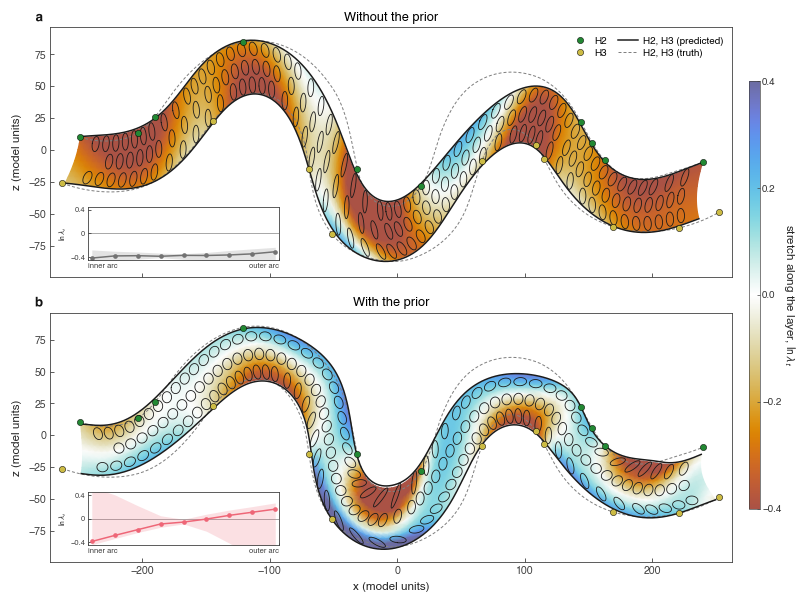

In [15]:
ELLIPSE_FRACS = (0.15, 0.5, 0.85)   # rows of ellipses, as shares of the layer's present thickness from H2 to H3
ELLIPSE_GAP = 0.12                  # space between ellipses along a row, in units of the unstrained radius
ELLIPSE_CLEAR = 1.                 # the one scale used is this share of the largest that clears the horizons
ELLIPSE_EDGE = 3                    # no ellipses this many points from the ends of the layer
CONTACT_SIZE = 14                   # marker area of the fitted contacts (pt^2)
STRETCH_LIM = 0.4                   # colour limit of the log stretch along the layer
HINGE_QUANTILE = 0.75               # c: points where the layer's curvature is above this quantile
KEYS = ("geometry", "prior")
n_across, n_along = (int(v) for v in r["layer_shape"])
H2, H3 = (horizons_full[i] for i in sli.COMPETENT)


def layer_geometry(key):
    # The fit's own competent layer: rows from its H2 (t = 0) to its H3 (t = 1), each a material line,
    # and the layer's direction and curvature from its middle row, shared by every row.
    XY = r[f"{key}_layer_xy"].reshape(n_across, n_along, 2)
    mid = XY[n_across // 2]
    d = np.gradient(mid, axis=0)
    tangent_mid = d / np.linalg.norm(d, axis=1, keepdims=True)
    angle = np.unwrap(np.arctan2(tangent_mid[:, 1], tangent_mid[:, 0]))
    curvature = np.gradient(angle) / np.linalg.norm(d, axis=1)            # > 0 turning anticlockwise
    # side: -1 on the inner arc and +1 on the outer arc. H2 is on top, so the outer arc is H2 where the
    # layer turns clockwise (an antiform, curvature < 0) and H3 where it turns anticlockwise.
    side = (1.0 - 2.0 * r["layer_t"])[:, None] * -np.sign(curvature)[None, :]
    hinge = np.abs(curvature) >= np.quantile(np.abs(curvature), HINGE_QUANTILE)
    return dict(XY=XY, tangent=np.broadcast_to(tangent_mid, XY.shape), side=side, hinge=hinge,
                top=r[f"{key}_layer_top"], bottom=r[f"{key}_layer_bottom"])


layers = {key: layer_geometry(key) for key in KEYS}


def along_layer_stretch(g, B):
    # Log stretch of the material line now along the layer: 1 / lambda^2 = t^T B^-1 t (B = F F^T, unit det).
    Binv = np.linalg.inv(B).reshape(n_across, n_along, 2, 2)
    return -0.5 * np.log(np.einsum("abi,abij,abj->ab", g["tangent"], Binv, g["tangent"]))


def present_rows(g, B):
    # Rows for the ellipses spaced evenly through the layer as it is now, not as it was: along each material
    # line across the layer (a column of the fill, H2 to H3), the points at ELLIPSE_FRACS of its present
    # length, with the strain interpolated there.
    XY, Bg = g["XY"], B.reshape(n_across, n_along, 2, 2)
    xy = np.empty((len(ELLIPSE_FRACS), n_along, 2))
    Bp = np.empty((len(ELLIPSE_FRACS), n_along, 2, 2))
    for j in range(n_along):
        length = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(XY[:, j], axis=0), axis=1))]
        u = np.interp(np.asarray(ELLIPSE_FRACS) * length[-1], length, np.arange(n_across))
        i0 = np.minimum(u.astype(int), n_across - 2)
        w = u - i0
        xy[:, j] = (1 - w)[:, None] * XY[i0, j] + w[:, None] * XY[i0 + 1, j]
        Bp[:, j] = (1 - w)[:, None, None] * Bg[i0, j] + w[:, None, None] * Bg[i0 + 1, j]
    return xy, Bp


def ellipse_scale(g, xy, Bp):
    # The largest radius at which the ellipses of every candidate point clear the fit's own horizons. An
    # ellipse of radius s around c is the set d^T B^-1 d = s^2, with d = x - c, so s is the smallest such distance.
    cols = slice(ELLIPSE_EDGE, n_along - ELLIPSE_EDGE)
    Binv = np.linalg.inv(Bp[:, cols]).reshape(-1, 2, 2)
    d = np.vstack([g["top"], g["bottom"]])[None] - xy[:, cols].reshape(-1, 1, 2)
    return np.sqrt(np.einsum("cpi,cij,cpj->cp", d, Binv, d).min())


def ellipse_points(xy, Bp, scale):
    # March along each row, placing each ellipse a fixed gap past the last. An ellipse's half-width along the
    # row is scale * sqrt(t^T B t), so where the layer is stretched the ellipses are wide along it and the
    # row carries few, and where it is shortened they are narrow and the row carries many.
    centres, Bs = [], []
    for k in range(len(ELLIPSE_FRACS)):
        step = np.gradient(xy[k], axis=0)
        t_row = step / np.linalg.norm(step, axis=1, keepdims=True)
        half = scale * np.sqrt(np.einsum("ci,cij,cj->c", t_row, Bp[k], t_row))
        length = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(xy[k], axis=0), axis=1))]
        j = ELLIPSE_EDGE + (3 if k % 2 else 0)                 # the centre row starts staggered
        while j < n_along - ELLIPSE_EDGE:
            centres.append(xy[k, j])
            Bs.append(Bp[k, j])
            ahead = np.arange(j + 1, n_along - ELLIPSE_EDGE)
            room = length[ahead] - length[j] - half[j] - half[ahead]
            fits = np.nonzero(room >= ELLIPSE_GAP * scale)[0]
            if not len(fits):
                break
            j = int(ahead[fits[0]])
    return np.array(centres), np.array(Bs)


def draw_ellipses(ax, centres, Bs, scale):
    t = np.linspace(0.0, 2.0 * np.pi, 48)
    circle = np.stack([np.cos(t), np.sin(t)])
    evals, evecs = np.linalg.eigh(Bs)
    verts = [(c[:, None] + scale * (f * np.sqrt(e)) @ circle).T for c, f, e in zip(centres, evecs, evals)]
    ax.add_collection(PolyCollection(verts, facecolors="none", edgecolors="0.1", linewidths=0.5, zorder=3))


rows_now = {key: present_rows(layers[key], r[f"{key}_B_layer"]) for key in KEYS}
scale_e = ELLIPSE_CLEAR * min(ellipse_scale(layers[key], *rows_now[key]) for key in KEYS)
print(f"radius of the unstrained circle {scale_e:.2f} model units")

# The constraints on the layer: the fitted contacts of H2 and H3 and the bedding, as in Fig. 3a.
names = [f"H{i}" for i in sli.COMPETENT]
contact_colors = {name: figstyle.HORIZON_PALETTE[i] for name, i in zip(names, sli.COMPETENT)}
contacts = [obs["horizons"][i] for i in sli.COMPETENT]

edges = np.vstack([H2, H3] + [layers[key][e] for key in KEYS for e in ("top", "bottom")])
pad = 10.0
xlim = (edges[:, 0].min() - pad, edges[:, 0].max() + pad)
zlim = (edges[:, 1].min() - pad, edges[:, 1].max() + pad)
left, right, gap, top = 0.55, 0.85, 0.30, 0.25             # right: the colour bar and its label
w = figstyle.PRINT_WIDTH - left - right
h = w * (zlim[1] - zlim[0]) / (xlim[1] - xlim[0])
bottom = 0.42
fig_h = top + 2 * h + gap + bottom
fig = figstyle.print_figure(height=fig_h)
fw = figstyle.PRINT_WIDTH
axes = [fig.add_axes([left / fw, (bottom + (1 - k) * (h + gap)) / fig_h, w / fw, h / fig_h]) for k in range(2)]
cmap = cmr.prinsenvlag
norm = plt.Normalize(-STRETCH_LIM, STRETCH_LIM)
stretch = {}
FIT_COLOR = {"geometry": "0.45", "prior": figstyle.HORIZON_PALETTE[4]}
for ax, key, title in ((axes[0], "geometry", "Without the prior"), (axes[1], "prior", "With the prior")):
    g, B = layers[key], r[f"{key}_B_layer"]
    stretch[key] = along_layer_stretch(g, B)
    ax.pcolormesh(g["XY"][..., 0], g["XY"][..., 1], stretch[key], cmap=cmap, norm=norm, shading="gouraud",
                  rasterized=True)
    centres_e, B_e = ellipse_points(*rows_now[key], scale_e)
    print(f"{key}: {len(centres_e)} ellipses")
    draw_ellipses(ax, centres_e, B_e, scale_e)
    for edge in (g["top"], g["bottom"]):                       # the fit's own H2 and H3
        ax.plot(*edge.T, color="0.1", lw=0.9, zorder=4)
    for trace in (H2, H3):                                     # the digitised traces
        ax.plot(*trace.T, color="0.5", lw=0.6, ls=(0, (3, 2)), zorder=2)
    figstyle.overlay_constraints(ax, contacts, names, obs["gp"], obs["gv"], colors=contact_colors,
                                 scatter_s=CONTACT_SIZE, show_quiver=False)
    ax.set_xlim(*xlim)
    ax.set_ylim(*zlim)
    ax.set_aspect("equal")
    ax.set_ylabel("z (model units)")
    ax.set_title(title)
axes[0].set_xticklabels([])

# Legend in a: the constraints, the fit's own horizons and the digitised traces
from matplotlib.lines import Line2D
handles = [Line2D([0], [0], ls="none", marker="o", ms=np.sqrt(CONTACT_SIZE), mfc=contact_colors[n], mec="k",
                  mew=0.3, label=f"{n}") for n in names]
handles += [Line2D([0], [0], color="0.1", lw=0.9, label="H2, H3 (predicted)"),
            Line2D([0], [0], color="0.5", lw=0.6, ls=(0, (3, 2)), label="H2, H3 (truth)")]
axes[0].legend(handles=handles, loc="upper right", ncol=2, frameon=True, framealpha=0.9, edgecolor="none",
               fontsize=figstyle.pt(8.5), handlelength=2.0, borderpad=0.4, labelspacing=0.35, columnspacing=1.2)
axes[1].set_xlabel("x (model units)")

# Insets: the stretch along the layer against position across it, at the hinges, on one scale in both panels
INSET = (xlim[0] + 30.0, zlim[0] + 13.0, 150.0, 42.0)      # x, z, width, height, in model units
for ax, key in zip(axes, KEYS):
    g = layers[key]
    pos = g["side"][:, g["hinge"]]
    val = stretch[key][:, g["hinge"]]
    order = np.argsort(pos.mean(axis=1))
    rows_pos = np.array([np.median(pos[i]) for i in order])
    med = np.array([np.median(val[i]) for i in order])
    q1 = np.array([np.percentile(val[i], 25) for i in order])
    q3 = np.array([np.percentile(val[i], 75) for i in order])
    inset = ax.inset_axes(INSET, transform=ax.transData)
    inset.fill_between(rows_pos, q1, q3, color=FIT_COLOR[key], alpha=0.2, lw=0)
    inset.plot(rows_pos, med, "o-", color=FIT_COLOR[key], ms=1.8, lw=0.9)
    inset.axhline(0.0, color="0.6", lw=0.5, zorder=0)
    inset.set_xlim(-1, 1)
    inset.set_ylim(-0.45, 0.45)
    inset.set_xticks([-1, 1], ["inner arc", "outer arc"])
    inset.set_yticks([-0.4, 0.0, 0.4], ["−0.4", "0", "0.4"])
    inset.tick_params(labelsize=figstyle.pt(6.5), length=1.5, pad=1.5)
    for tick, ha in zip(inset.get_xticklabels(), ("left", "right")):
        tick.set_ha(ha)
    inset.set_ylabel(r"$\ln\lambda_t$", fontsize=figstyle.pt(6.5), labelpad=1)

pa, pb = axes[0].get_position(), axes[1].get_position()     # one colour bar for both panels
cax = fig.add_axes([pa.x1 + 0.14 / fw, pb.y0 + 0.1 * (pa.y1 - pb.y0), 0.09 / fw, 0.8 * (pa.y1 - pb.y0)])
figstyle.add_cbar(cax, plt.cm.ScalarMappable(norm=norm, cmap=cmap), r"stretch along the layer, $\ln\lambda_t$")
for ax, letter in zip(axes, "ab"):
    figstyle.panel_label(ax, letter)
figstyle.save(fig, FIG_DIR / "fig03_single_layer_strain_prior")
plt.show()


## Numbers quoted in the text

In [ ]:
for key in KEYS:
    g = layers[key]
    at_hinge, across = stretch[key][:, g["hinge"]], g["side"][:, g["hinge"]].mean(1)
    inner, outer = at_hinge[np.argmin(across)], at_hinge[np.argmax(across)]
    print(f"{key}: log stretch along the layer at the hinges, inner arc {np.median(inner):.2f}, outer arc {np.median(outer):.2f}")
